# eBird: from checklists to candidate cards

Follow a real eBird project export into linked atlas tables. These are **candidate cards**, not verified ABAP submissions. Install the environment with `uv sync --frozen`; the input export and taxonomy are supplied separately.

## The workflow

The eBird path runs from an observation export and taxonomy through preparation to the green dataset. Blue is source data, orange is curated taxonomy, purple is processing, and green is output. The diagram is the same one used in the project README.

```mermaid
flowchart LR
    EBD[/eBird Basic Dataset<br/>species observations/] --> EP(eBird preparation)
    PROJECT[/eBird project export/] --> EP
    API([BirdMap API]) --> DOWNLOAD(ABAP download)
    DOWNLOAD --> RAW[/Downloaded ABAP snapshot/]
    RAW --> AP(ABAP preparation)
    SUPPLIED[/Supplied ABAP export<br/>adapter pending/] -.-> AP
    TAX[/eBird taxonomy<br/>declared version and provenance/] --> EP
    TAX --> AP
    CROSS[/Curated ABAP crosswalk<br/>and regional decisions/] --> AP
    PENTAD[[Shared pentad functions]] -.-> EP
    PENTAD -.-> AP
    EP --> E[(Prepared eBird dataset)]
    AP --> A[(Prepared ABAP dataset)]
    E --> COMBINE(Combine datasets)
    A --> COMBINE
    COMBINE --> C[(Combined dataset<br/>compatible taxonomy provenance)]

    classDef external fill:#e5effa,stroke:#356796,color:#153e62
    classDef curated fill:#fff0d2,stroke:#976a10,color:#583900
    classDef process fill:#e9e5f6,stroke:#6553a0,color:#352961
    classDef utility fill:#f1f1f1,stroke:#666,color:#222
    classDef output fill:#dff2e8,stroke:#287a50,color:#164a2f
    class EBD,PROJECT,API,RAW,SUPPLIED,TAX external
    class CROSS curated
    class DOWNLOAD,EP,AP,COMBINE process
    class PENTAD utility
    class E,A,C output
```

In [1]:
from pathlib import Path
import json
import subprocess
import sys
import tempfile

import matplotlib.pyplot as plt
import pandas as pd

root = Path.cwd() if (Path.cwd() / 'bird_atlas').is_dir() else Path.cwd().parent
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False, 'axes.spines.right': False})

## 1. Choose the observations

This example uses the African Bird Atlas Project species-observation export from 28 October 2026. The package also accepts an eBird Basic Dataset (EBD). Set `download_ebd = True` to download an African release; preparation uses a trimmed disk cache and complete-observer batches. For a full release, follow [the laptop guide](../docs/ebird-preparation.md#running-a-full-africa-release-on-a-laptop) and reuse an explicit cache path.

In [2]:
download_ebd = False
if download_ebd:
    subprocess.run([sys.executable, str(root / 'scripts/ebird/download.py'),
                    '--year', '2026', '--month', 'Sep',
                    '--output', str(root / 'data/raw/ebird')], cwd=root, check=True)

source = root / 'data/raw/ebird/project-report-123e8236-edc1-4643-bba6-c0591861449f/project-1056-report-20261028_1745.txt'
source_kind = 'project'
print('Input:', source.relative_to(root))

Input: data/raw/ebird/project-report-123e8236-edc1-4643-bba6-c0591861449f/project-1056-report-20261028_1745.txt


The source is *eBird Project: African Bird Atlas Project*, version 28 October 2026 (Cornell Lab of Ornithology). Consult the supplied `terms_of_use.txt` and `recommended_citation.txt` when using or sharing data.

## 2. Choose the taxonomy

The reference must match the observations. This demonstration uses the local eBird 2026 reference, but the export's taxonomy version has **not been verified**. Check the source metadata and use the matching reference before research use.

In [3]:
taxonomy = root / 'data/taxonomy/ebird_2026.csv'
ebird_version = '2026'  # Demonstration assumption; verify against the source before analysis.
print('Declared taxonomy:', ebird_version, '| Reference:', taxonomy.relative_to(root))

Declared taxonomy: 2026 | Reference: data/taxonomy/ebird_2026.csv


## 3. Build candidate cards

The package groups checklists by observer and pentad. A candidate card needs at least two hours of qualifying, non-overlapping effort within five calendar days. Shared submissions count once; other observations can add species without adding qualifying effort. This example uses a temporary folder; choose a new folder under `data/prepared/` to keep the result.

In [4]:
temporary = tempfile.TemporaryDirectory(prefix='bird-atlas-ebird-')
output = Path(temporary.name) / 'prepared'
result = subprocess.run([sys.executable, str(root / 'scripts/ebird/prepare.py'),
                         '--input', str(source), '--output', str(output),
                         '--taxonomy', str(taxonomy), '--ebird-version', ebird_version,
                         '--source-kind', source_kind], cwd=root, check=True, capture_output=True, text=True)
print(result.stdout or 'Preparation completed.')
print(result.stderr)

Preparation completed.
scripts/ebird/prepare.py:14: UserWarning: 80 observation rows have no eligible eBird taxon; see excluded_observations.csv.gz
  export_ebird(args.input, args.output, taxonomy_file=args.taxonomy, ebird_version=args.ebird_version, source_kind=args.source_kind, keep_missing_distance=not args.exclude_missing_distance)



In [5]:
result = subprocess.run([sys.executable, str(root / 'scripts/shared/validate.py'), str(output)],
                        cwd=root, check=True, capture_output=True, text=True)
print(result.stdout)

Valid shared keys: 35 cards, 1457 records, 538 taxa.



## 4. See how checklists become a card

These are the real qualifying submissions for one card on 5 September 2026. The two observers submitted the same six activities, so each pair is counted once. Here the six activities do not overlap; elsewhere, overlapping time is also counted once.

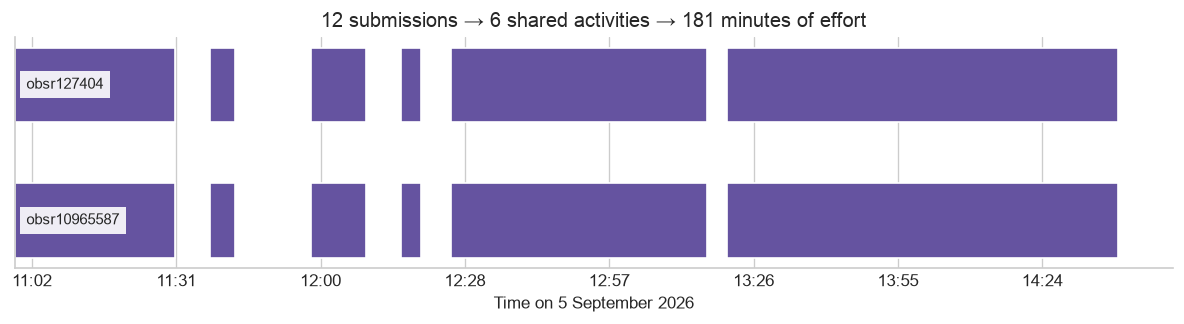

In [6]:
import matplotlib.dates as mdates

cards = pd.read_csv(output / 'cards.csv', dtype={'pentad_id': str})
checklists = pd.read_csv(output / 'checklist.csv')
example_card = '0115_3500_obsr127404_20260905'
card = cards.set_index('card_id').loc[example_card]
submissions = checklists[checklists['card_id'].eq(example_card) & checklists['card_effort_eligible']].copy()
submissions['start'] = pd.to_datetime(submissions['start_date'] + ' ' + submissions['start_time'])
fig, ax = plt.subplots(figsize=(10, 2.8))
for y, (observer, rows) in enumerate(submissions.groupby('observer_id', sort=True)):
    ax.barh(y, rows['duration_minutes'] / 1440, left=mdates.date2num(rows['start']), height=0.55, color='#6553a0', edgecolor='white')
    ax.text(0.01, y, observer, transform=ax.get_yaxis_transform(), va='center', ha='left', fontsize=9,
            bbox=dict(facecolor='white', edgecolor='none', alpha=0.9))
ax.set_yticks([])
ax.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
ax.set(title=f"12 submissions → 6 shared activities → {card['duration_minutes']:.0f} minutes of effort", xlabel='Time on 5 September 2026')
fig.tight_layout()

## 5. Follow the card into the output

`checklist.csv` keeps each submission and its shared `checklist_group_id`. `cards.csv` summarizes the card; `records.csv.gz` contains one taxon presence per card; `species.csv` supplies names and `pentads.csv` supplies locations. Card observer IDs are JSON lists.

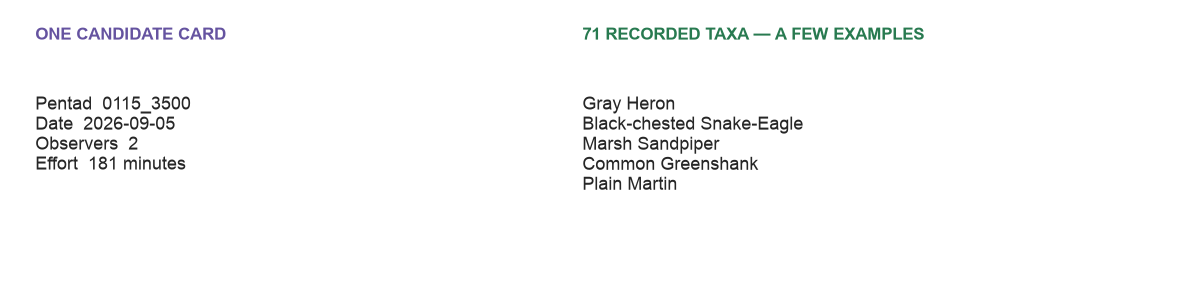

In [7]:
records = pd.read_csv(output / 'records.csv.gz')
species = pd.read_csv(output / 'species.csv')
card_species = records[records['card_id'].eq(example_card)].merge(species, on='ebird_avibase_id')
observers = json.loads(card['observer_id'])
fig, ax = plt.subplots(figsize=(10, 2.6))
ax.axis('off')
ax.text(0.02, 0.90, 'ONE CANDIDATE CARD', transform=ax.transAxes, weight='bold', color='#6553a0')
ax.text(0.02, 0.70, f"Pentad  {card['pentad_id']}\nDate  {card['start_date']}\nObservers  {len(observers)}\nEffort  {card['duration_minutes']:.0f} minutes", transform=ax.transAxes, va='top', fontsize=11)
ax.text(0.49, 0.90, f"{len(card_species)} RECORDED TAXA — A FEW EXAMPLES", transform=ax.transAxes, weight='bold', color='#287a50')
ax.text(0.49, 0.70, '\n'.join(card_species['common_name'].dropna().head(5)), transform=ax.transAxes, va='top', fontsize=11)
fig.tight_layout()

Before research use, verify the taxonomy version and review `excluded_observations.csv.gz` and the checklist diagnostics in `audit/`. Project exports assume pentad containment. When combining datasets, prepare them against the same taxonomy reference; eBird records are card–taxon presences, while ABAP records are retained source detections.